# 07 — Deployment simulation: update frequency × budget (RQ4, rel-f1)

**Purpose.** Test the RQ4 machinery on driver-dnf.

- **Shared start.** One model is trained up to t0. Every configuration adopts it.
- **Configurations.** Each one (regime, update interval ΔI, steps per update B)
  then updates on its own schedule.
- **Timeline score.** Every anchor after t0 is predicted by the latest model
  updated before it. The score is the mean over anchor times, with a
  block-bootstrap interval, because neighbouring anchors are correlated.
- **Cost.** Updates × B steps, plus measured training seconds.
- **Pareto front** of cost against score.

rel-f1 is not an RQ4 dataset in the paper (too few rows per update); here it only
exercises the machinery.

**Gate.**
1. Every configuration covers the same anchor times after t0, and every anchor
   has a model.
2. Timeline scores and their intervals are finite.
3. The Pareto front is computed.

In [1]:
DATASET = "rel-f1"
TASK = "driver-dnf"
DEVICE = "auto"
SCALE = "smoke"
OUT = "notebooks/methodology/out"
THREADS = 8
HOLDOUT_FRAC = 0.2
T0 = "2020-01-01"
DELTA_I_DAYS = [30, 60, 120, 365, 0]  # 0 = never update after t0
BUDGETS = [50, 200]
REGIMES = ["incremental", "cumulative", "scratch_all"]
INIT_STEPS = 2000
BLOCK = 3

In [2]:
# Parameters
SCALE = "smoke"
DEVICE = "cpu"


In [3]:
import json
import os
import shutil
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from experiments.continuous_learning.chain_runner import ChainConfig, build_context, run_chain
from redelex.continual import analysis as A

torch.set_num_threads(THREADS)
if SCALE == "smoke":
    DELTA_I_DAYS, BUDGETS, REGIMES, INIT_STEPS = [365, 0], [20], ["incremental", "cumulative"], 60
out = Path(OUT)
work = out / "07_rq4"
if SCALE == "smoke":
    shutil.rmtree(work, ignore_errors=True)


def cfg(mode, variant, **kw):
    base = dict(device=DEVICE, torch_threads=THREADS, holdout_frac=HOLDOUT_FRAC, anytime=False, stale_windows=0)
    base.update(kw)
    return ChainConfig(DATASET, TASK, mode, 0, str(work), variant=variant, **base)

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## The shared model at t0

Scratch on all labelled history up to t0, trained to convergence. Its first
update time is t0, and every configuration adopts it.

In [4]:
init_cfg = cfg("scratch_all", "init", first_update=T0, delta_i_days=0, max_steps=INIT_STEPS,
               check_every=min(50, INIT_STEPS // 4), patiences=(5,))
run_chain(init_cfg)
init_model = init_cfg.seed_dir() / "ep001" / "model.pt"
print("shared model at", T0, ":", init_model)

Loading Database object from /home/pelesjak/.cache/relbench/rel-f1/db...
Done in 0.07 seconds.


/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.se

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


shared model at 2020-01-01 : notebooks/methodology/out/07_rq4/rel-f1__driver-dnf__scratch_all__init/seed0/ep001/model.pt


## Every configuration

In [5]:
configs = []
for mode in REGIMES:
    for di in DELTA_I_DAYS:
        for b in BUDGETS if di else BUDGETS[:1]:  # ΔI = ∞ never trains: one budget is enough
            variant = f"di{di}_b{b}"
            c = cfg(mode, variant, first_update=T0, delta_i_days=di, stop_rule="budget", max_steps=b,
                    init_model=str(init_model))
            summary = run_chain(c)
            configs.append({"mode": mode, "ΔI days": di if di else np.inf, "B": b if di else 0, "cfg": c,
                            "updates": summary["episodes_done"]})
pd.DataFrame(configs).drop(columns="cfg")

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.se

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


...

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.se

/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(
/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch_frame/data/dataset.py:587: UserWarning: Weights only load failed. Please file an issue to make `torch.load(weights_only=True)` compatible in your case. Please use `torch.serialization.add_safe_globals([numpy.core.multiarray.scalar])` to allowlist this global.
  self._tensor_frame, self._col_stats = torch_frame.load(


/home/pelesjak/redelex/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


,mode,ΔI days,B,updates
0,incremental,365.0,20,4
1,incremental,inf,0,1
2,cumulative,365.0,20,4
3,cumulative,inf,0,1


## Timeline score and cost

In [6]:
results, timelines = [], {}
t0 = pd.Timestamp(T0)
for row in configs:
    c = row["cfg"]
    rows = pd.read_parquet(c.chain_root() / "rows.parquet")
    eps = sorted(c.seed_dir().glob("ep*"))
    preds = {int(p.name[2:]): pd.read_parquet(p / "preds.parquet") for p in eps}
    recs = [json.loads((p / "episode.json").read_text()) for p in eps]
    metric = recs[0]["metric"]
    tl = A.timeline_scores(rows, preds, metric, start=t0)
    mean, lo, hi = A.block_bootstrap_ci(tl, block=BLOCK, n_boot=1000)
    cost = A.horizon_cost(recs)
    key = (row["mode"], row["ΔI days"], row["B"])
    timelines[key] = tl
    results.append({"mode": row["mode"], "ΔI days": row["ΔI days"], "B": row["B"], "updates": row["updates"],
                    "steps": cost["steps"], "train s": round(cost["train_seconds"], 1),
                    "anchor times": len(tl), "score": mean, "ci low": lo, "ci high": hi})
results = pd.DataFrame(results)
results["pareto"] = A.pareto_front(results["steps"], results["score"])
results.sort_values(["mode", "ΔI days", "B"]).round(4)

,mode,ΔI days,B,updates,steps,train s,anchor times,score,ci low,ci high,pareto
2,cumulative,365.0,20,4,60,47.1,32,0.7685,0.7304,0.8188,False
3,cumulative,inf,0,1,0,0.0,32,0.7737,0.7431,0.8268,True
0,incremental,365.0,20,4,60,68.8,32,0.7356,0.6962,0.7899,False
1,incremental,inf,0,1,0,0.0,32,0.7737,0.7431,0.8268,True


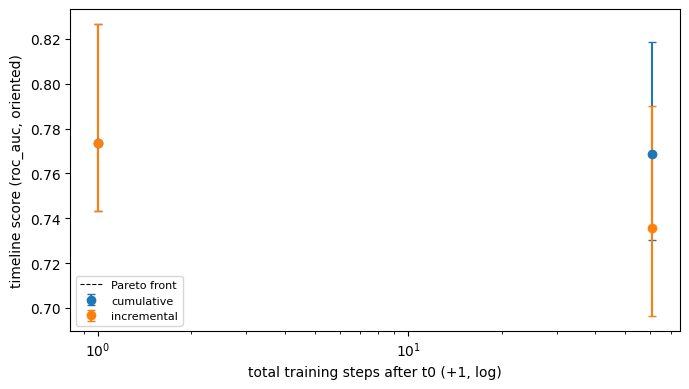

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for mode, g in results.groupby("mode"):
    ax.errorbar(g["steps"] + 1, g["score"], yerr=[g["score"] - g["ci low"], g["ci high"] - g["score"]],
                fmt="o", capsize=3, label=mode)
front = results[results.pareto].sort_values("steps")
ax.plot(front["steps"] + 1, front["score"], "k--", lw=0.8, label="Pareto front")
ax.set_xscale("log")
ax.set_xlabel("total training steps after t0 (+1, log)")
ax.set_ylabel(f"timeline score ({metric}, oriented)")
ax.legend(fontsize=8)
fig.tight_layout()

## Gate

In [8]:
lengths = {k: len(v) for k, v in timelines.items()}
assert len(set(lengths.values())) == 1, lengths  # every configuration covers the same anchor times
any_tl = next(iter(timelines.values()))
assert any_tl.index.min() >= t0
assert np.isfinite(results[["score", "ci low", "ci high"]].to_numpy()).all(), results
assert results["pareto"].any()
(out / f"07_rq4_{DATASET}_{SCALE}.json").write_text(results.to_json(orient="records", indent=2))
print("GATE 07 PASSED")

GATE 07 PASSED
